# D2 – Image Features
## 1. Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from library.gmm import GMM
from library.knn import KNN
from library.lda import LDA
from library.pca import PCA
from library.svm import SVM

def show_plots(X, y):
    X = X - X.mean(axis=0)

    _, _, V = np.linalg.svd(X, full_matrices=False)
    points = X @ V[:2].T

    for label in np.unique(y):
        mask = y == label
        plt.scatter(points[mask, 0], points[mask, 1], s=10, label=label)

    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.show()

## 2. Load Data

In [2]:
def load_split_data(dataset_type):
    feature_file = f"./data/image_features/{dataset_type}_data.csv"
    label_file = f"./data/image_features/{dataset_type}_label.csv"

    feature_matrix = np.loadtxt(feature_file, delimiter=",")
    target_values = np.loadtxt(label_file, delimiter=",").astype(int)

    return feature_matrix, target_values


train_features, train_labels = load_split_data("train")
valid_features, valid_labels = load_split_data("val")
test_features, test_labels = load_split_data("test")

class_labels = np.unique(train_labels)

print("Available classes:", class_labels)
print("Training samples:", train_features.shape)
print("Validation samples:", valid_features.shape)
print("Testing samples:", test_features.shape)

Available classes: [0 1 2 3 4]
Training samples: (2000, 36)
Validation samples: (500, 36)
Testing samples: (500, 36)


## 3. 2D PCA Visualization & Evaluation Setup

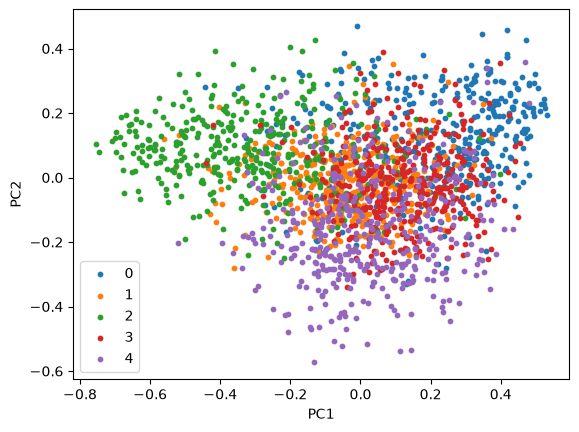

In [3]:
show_plots(train_features, train_labels)

def build_confusion_matrix(actual, predicted, labels):
    matrix = np.zeros((len(labels), len(labels)), dtype=int)

    for row, actual_class in enumerate(labels):
        for column, predicted_class in enumerate(labels):
            matrix[row, column] = np.count_nonzero(
                (actual == actual_class) & (predicted == predicted_class)
            )
    return matrix

## 4. Models Without PCA
### GMM

In [4]:
gmm_models = []
class_priors = []

for label in class_labels:
    class_samples = train_features[train_labels == label]
    model = GMM(n_components=3, regularization=1e-3, iterations=100, convergence_tol=1e-4)
    model.fit(class_samples)
    gmm_models.append(model)
    class_priors.append(len(class_samples) / len(train_features))
    print("Class", label, "EM iterations:", len(model.log_likelihoods))
    if len(model.log_likelihoods) == model.iterations:
        print("Iteration limit reached; convergence is not guaranteed.")

valid_scores = np.column_stack([m.score_samples(valid_features) for m in gmm_models])
gmm_valid_preds = class_labels[np.argmax(valid_scores + np.log(class_priors), axis=1)]

test_scores = np.column_stack([m.score_samples(test_features) for m in gmm_models])
gmm_test_preds = class_labels[np.argmax(test_scores + np.log(class_priors), axis=1)]

gmm_confusion = build_confusion_matrix(test_labels, gmm_test_preds, class_labels)

print("Validation accuracy:", np.mean(gmm_valid_preds == valid_labels))
print("Test accuracy:", np.mean(gmm_test_preds == test_labels))
print("Test confusion matrix:\n", gmm_confusion)

Class 0 EM iterations: 18
Class 1 EM iterations: 24
Class 2 EM iterations: 17
Class 3 EM iterations: 29
Class 4 EM iterations: 19
Validation accuracy: 0.68
Test accuracy: 0.674
Test confusion matrix:
 [[79  7  5  6  3]
 [ 7 59  7 13 14]
 [ 4 18 70  4  4]
 [10 16  4 66  4]
 [ 3 19  2 13 63]]


### KNN

In [5]:
knn_model = KNN(neighbors=5)
knn_model.fit(train_features, train_labels)

knn_valid_preds = knn_model.predict(valid_features)
knn_test_preds = knn_model.predict(test_features)

knn_confusion = build_confusion_matrix(test_labels, knn_test_preds, class_labels)

print("Validation accuracy:", np.mean(knn_valid_preds == valid_labels))
print("Test accuracy:", np.mean(knn_test_preds == test_labels))
print("Test confusion matrix:\n", knn_confusion)

Validation accuracy: 0.676
Test accuracy: 0.684
Test confusion matrix:
 [[73 15  3  7  2]
 [ 4 66  9 14  7]
 [ 1 19 75  3  2]
 [ 6 13  4 72  5]
 [ 3 26  4 11 56]]


### LDA

In [6]:
lda_model = LDA()
lda_model.fit(train_features, train_labels)

lda_valid_preds = lda_model.predict(valid_features)
lda_test_preds = lda_model.predict(test_features)

lda_confusion = build_confusion_matrix(test_labels, lda_test_preds, class_labels)

print("Validation accuracy:", np.mean(lda_valid_preds == valid_labels))
print("Test accuracy:", np.mean(lda_test_preds == test_labels))
print("Test confusion matrix:\n", lda_confusion)

Validation accuracy: 0.702
Test accuracy: 0.698
Test confusion matrix:
 [[80  9  1  9  1]
 [ 4 71  4 10 11]
 [ 1 21 71  6  1]
 [14  9  3 60 14]
 [ 5 18  3  7 67]]


### SVM

In [7]:
svm_model = SVM()
svm_model.fit(train_features, train_labels)

print("One-vs-rest classifiers:", len(svm_model.models))
print("Gaussian sigma:", svm_model.width)
print("Converged:", svm_model.converged)
print("Largest KKT gap:", max(svm_model.gaps))
if not svm_model.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")

svm_valid_preds = svm_model.predict(valid_features)
svm_test_preds = svm_model.predict(test_features)

svm_confusion = build_confusion_matrix(test_labels, svm_test_preds, class_labels)

print("Validation accuracy:", np.mean(svm_valid_preds == valid_labels))
print("Test accuracy:", np.mean(svm_test_preds == test_labels))
print("Test confusion matrix:\n", svm_confusion)

One-vs-rest classifiers: 5
Gaussian sigma: 0.2677842617035123
Converged: True
Largest KKT gap: 0.0009989039874599426
Validation accuracy: 0.752
Test accuracy: 0.724
Test confusion matrix:
 [[85  7  4  3  1]
 [ 5 62  6 19  8]
 [ 4 12 78  3  3]
 [ 8  9  4 75  4]
 [ 6 17  3 12 62]]


## 5. Dimensionality Reduction (PCA)

In [8]:
num_components = 18
pca_transformer = PCA(n_components=num_components)
pca_transformer.fit(train_features)

train_features_pca = pca_transformer.transform(train_features)
valid_features_pca = pca_transformer.transform(valid_features)
test_features_pca = pca_transformer.transform(test_features)

print("Training PCA shape:", train_features_pca.shape)
print("Validation PCA shape:", valid_features_pca.shape)
print("Testing PCA shape:", test_features_pca.shape)

Training PCA shape: (2000, 18)
Validation PCA shape: (500, 18)
Testing PCA shape: (500, 18)


## 6. Models With PCA
### GMM with PCA

In [9]:
pca_gmm_models = []
pca_class_priors = []

for label in class_labels:
    pca_samples = train_features_pca[train_labels == label]
    pca_model = GMM(n_components=3, regularization=1e-3, iterations=100, convergence_tol=1e-4)
    pca_model.fit(pca_samples)
    pca_gmm_models.append(pca_model)
    pca_class_priors.append(len(pca_samples) / len(train_features_pca))
    print("Class", label, "EM iterations:", len(pca_model.log_likelihoods))
    if len(pca_model.log_likelihoods) == pca_model.iterations:
        print("Iteration limit reached; convergence is not guaranteed.")

pca_valid_scores = np.column_stack([m.score_samples(valid_features_pca) for m in pca_gmm_models])
gmm_pca_valid_preds = class_labels[np.argmax(pca_valid_scores + np.log(pca_class_priors), axis=1)]

pca_test_scores = np.column_stack([m.score_samples(test_features_pca) for m in pca_gmm_models])
gmm_pca_test_preds = class_labels[np.argmax(pca_test_scores + np.log(pca_class_priors), axis=1)]

gmm_pca_confusion = build_confusion_matrix(test_labels, gmm_pca_test_preds, class_labels)

print("Validation accuracy:", np.mean(gmm_pca_valid_preds == valid_labels))
print("Test accuracy:", np.mean(gmm_pca_test_preds == test_labels))
print("Test confusion matrix:\n", gmm_pca_confusion)

Class 0 EM iterations: 12
Class 1 EM iterations: 76
Class 2 EM iterations: 23
Class 3 EM iterations: 10
Class 4 EM iterations: 23
Validation accuracy: 0.686
Test accuracy: 0.71
Test confusion matrix:
 [[80  7  5  6  2]
 [ 3 68  7 16  6]
 [ 2 15 75  4  4]
 [11 10  3 72  4]
 [ 2 21  6 11 60]]


### KNN with PCA

In [10]:
knn_pca_model = KNN(neighbors=5)
knn_pca_model.fit(train_features_pca, train_labels)

knn_pca_valid_preds = knn_pca_model.predict(valid_features_pca)
knn_pca_test_preds = knn_pca_model.predict(test_features_pca)

knn_pca_confusion = build_confusion_matrix(test_labels, knn_pca_test_preds, class_labels)

print("Validation accuracy:", np.mean(knn_pca_valid_preds == valid_labels))
print("Test accuracy:", np.mean(knn_pca_test_preds == test_labels))
print("Test confusion matrix:\n", knn_pca_confusion)

Validation accuracy: 0.696
Test accuracy: 0.702
Test confusion matrix:
 [[73 14  1 10  2]
 [ 5 72  8 11  4]
 [ 3 14 78  3  2]
 [ 7 14  5 68  6]
 [ 1 24  5 10 60]]


### LDA with PCA

In [11]:
lda_pca_model = LDA()
lda_pca_model.fit(train_features_pca, train_labels)

lda_pca_valid_preds = lda_pca_model.predict(valid_features_pca)
lda_pca_test_preds = lda_pca_model.predict(test_features_pca)

lda_pca_confusion = build_confusion_matrix(test_labels, lda_pca_test_preds, class_labels)

print("Validation accuracy:", np.mean(lda_pca_valid_preds == valid_labels))
print("Test accuracy:", np.mean(lda_pca_test_preds == test_labels))
print("Test confusion matrix:\n", lda_pca_confusion)

Validation accuracy: 0.696
Test accuracy: 0.702
Test confusion matrix:
 [[78 13  1  7  1]
 [ 4 70  4 10 12]
 [ 1 22 71  5  1]
 [11 11  2 65 11]
 [ 5 15  4  9 67]]


### SVM with PCA

In [12]:
svm_pca_model = SVM()
svm_pca_model.fit(train_features_pca, train_labels)

print("One-vs-rest classifiers:", len(svm_pca_model.models))
print("Gaussian sigma:", svm_pca_model.width)
print("Converged:", svm_pca_model.converged)
print("Largest KKT gap:", max(svm_pca_model.gaps))
if not svm_pca_model.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")

svm_pca_valid_preds = svm_pca_model.predict(valid_features_pca)
svm_pca_test_preds = svm_pca_model.predict(test_features_pca)

svm_pca_confusion = build_confusion_matrix(test_labels, svm_pca_test_preds, class_labels)

print("Validation accuracy:", np.mean(svm_pca_valid_preds == valid_labels))
print("Test accuracy:", np.mean(svm_pca_test_preds == test_labels))
print("Test confusion matrix:\n", svm_pca_confusion)

One-vs-rest classifiers: 5
Gaussian sigma: 0.24382521293050316
Converged: True
Largest KKT gap: 0.0009983343619834883
Validation accuracy: 0.73
Test accuracy: 0.688
Test confusion matrix:
 [[77 11  5  6  1]
 [ 2 62  7 21  8]
 [ 3 10 78  4  5]
 [ 9  9  3 72  7]
 [ 3 19  6 17 55]]


## 7. Accuracy Comparison

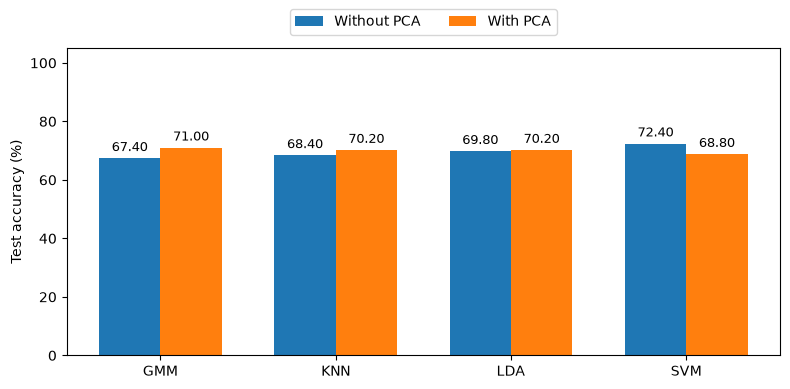

In [13]:
baseline_accuracies = [
    100 * np.trace(cm) / cm.sum()
    for cm in [gmm_confusion, knn_confusion, lda_confusion, svm_confusion]
]
pca_accuracies = [
    100 * np.trace(cm) / cm.sum()
    for cm in [gmm_pca_confusion, knn_pca_confusion, lda_pca_confusion, svm_pca_confusion]
]

positions = np.arange(4)
bar_width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
baseline_bars = ax.bar(positions - bar_width / 2, baseline_accuracies, bar_width, label="Without PCA")
pca_bars = ax.bar(positions + bar_width / 2, pca_accuracies, bar_width, label="With PCA")

ax.bar_label(baseline_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pca_bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(positions, ["GMM", "KNN", "LDA", "SVM"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2)
plt.tight_layout()
plt.show()